# 09 — Training a parking attendant, then checking its mistakes

Imagine teaching an attendant with photos from three different car parks. **Training** photos are practice questions with answers. **Validation** photos help choose the model and decide whether it is useful. **Final-test** photos are the sealed exam: we leave them closed while developing the model.

Our first classifier trained on two camera views. This study adds previously designated training dates from the third view. It trains only the small decision layer on frozen ResNet image features. The original model stays intact. This notebook reads a completed experiment; running it does **not** repeat training or open final-test photos.

In [1]:
from pathlib import Path
import json, sys
from IPython.display import display, HTML
from html import escape
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/'src'))
from smart_parking.holdouts import assert_holdout_closed
PINNED_RUN = 'OCCUPANCY-HEAD-20261026T012842296860Z'
folder = ROOT/'experiments/results'/PINNED_RUN
study = json.loads((folder/'run.json').read_text(encoding='utf-8'))
data = json.loads((ROOT/'experiments/results'/'OCCUPANCY-EXPANSION-DATA-20261026T012414713476Z'/'run.json').read_text(encoding='utf-8'))
assert study['final_images_or_labels_read'] == 0
later_final = ROOT/'models/occupancy_expansion_final.json'
if later_final.exists():
    final_record = json.loads(later_final.read_text(encoding='utf-8'))
    assert final_record['all_final_groups_now_consumed']
    print('Training used no final images. A later paired final is now complete; those date groups are consumed.')
else:
    assert_holdout_closed(ROOT/'data/manifests/pklot_fresh_final_v2.json', root=ROOT)
print('Recorded experiment:', PINNED_RUN)
print('Archived development evidence only. This lesson does not repeat training or final evaluation.')

Training used no final images. A later paired final is now complete; those date groups are consumed.
Recorded experiment: OCCUPANCY-HEAD-20261026T012842296860Z
Archived development evidence only. This lesson does not repeat training or final evaluation.


In [2]:
def table(records, columns=None):
    records = list(records)
    if not records:
        print('No rows.'); return
    columns = columns or list(records[0])
    def value(item):
        return escape(f'{item:.4f}' if isinstance(item,float) else str(item))
    header = '<tr>' + ''.join('<th>'+escape(c)+'</th>' for c in columns) + '</tr>'
    body = ''.join('<tr>'+''.join('<td>'+value(r.get(c,''))+'</td>' for c in columns)+'</tr>' for r in records)
    display(HTML('<table>'+header+body+'</table>'))

## 1. Which examples did we use?

All photos and original occupancy labels come from **PKLot, SRC-DS-001**. The ResNet starting features are attributed to **TorchVision/ImageNet, SRC-MOD-003**. Exact URLs, rights, archive-member names and checksums are in the source registry, resource receipts and qualification card.

A missing label means “we do not know the answer.” It must never be silently changed to “empty.” Several slots share the same photo, and repeated photos show the same spaces; these are correlated observations.

In [3]:
coverage = data['summary']['label_coverage']
table(coverage,['role','camera_id','frames','explicit_labels','unknown_labels','vacant_labels','occupied_labels'])
print('Training dates:', data['summary']['train_dates'], '| Validation dates:', data['summary']['validation_dates'])
print('Missing labels excluded:', sum(r['unknown_labels'] for r in coverage))
table(study['training_strata'])

role,camera_id,frames,explicit_labels,unknown_labels,vacant_labels,occupied_labels
train,pucpr,80,7304,696,4293,3011
train,ufpr04,66,1842,6,1033,809
train,ufpr05,24,958,2,591,367
validation,pucpr,12,804,396,168,636
validation,ufpr04,8,224,0,191,33
validation,ufpr05,25,1000,0,318,682


Training dates: 32 | Validation dates: 12
Missing labels excluded: 1100


camera_id,label,count
pucpr,0,4293
pucpr,1,3011
ufpr04,0,1033
ufpr04,1,809
ufpr05,0,591
ufpr05,1,367


## 2. What happened during learning?

An epoch is one pass over the training examples. It is not a new experiment. The best epoch is selected by the validation loss, with early stopping after six epochs without a sufficient improvement. Camera/class balancing uses training counts only.

The two loss curves use different weighting, so compare their trends rather than treating their numerical sizes as the same measurement.

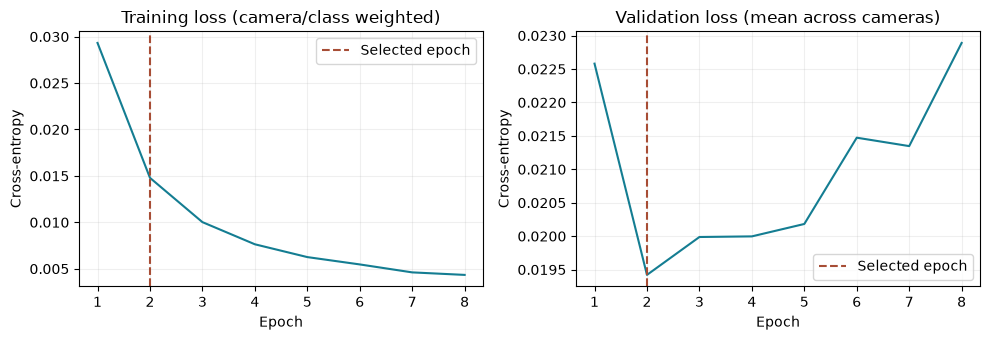

Completed epochs: 8 | Selected epoch: 2


In [4]:
curves = json.loads((folder/'curves.json').read_text(encoding='utf-8'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, column, title in zip(axes,
    ['train_weighted_cross_entropy','validation_macro_camera_cross_entropy'],
    ['Training loss (camera/class weighted)','Validation loss (mean across cameras)']):
    ax.plot([r['epoch'] for r in curves], [r[column] for r in curves], color='#147d92')
    ax.axvline(study['selected_epoch'], color='#a74d35', linestyle='--', label='Selected epoch')
    ax.set(xlabel='Epoch', ylabel='Cross-entropy', title=title)
    ax.grid(alpha=.2); ax.legend()
fig.tight_layout(); plt.show()
print('Completed epochs:', study['epochs_completed'], '| Selected epoch:', study['selected_epoch'])

## 3. Is the new model actually better?

**Wrong empty** means directing a driver to an occupied space. **Wrong occupied** means overlooking a usable empty space. **Needs review** means the model has not made a definite decision. We report all three; refusing more answers must not be presented as universal accuracy.

The first table uses all 2,028 labelled validation spaces. The second uses the same 720 recently reserved development examples from the earlier comparison. Neither table is a final-test or live camera score.

In [5]:
def row(name, values):
    return {'Model':name, 'Examples':values['samples'], 'Forced yes/no errors':values['hard_errors'],
            'Forced yes/no accuracy':values['hard_accuracy'], 'Wrong empty':values['false_vacant'],
            'Correct empty':values['correct_vacant_predictions'], 'Wrong occupied':values['false_occupied'],
            'Needs review':values['uncertain']}
table([row('Original',study['baseline']['overall']),row('Candidate',study['candidate']['overall'])])
table([row('Original: fresh development',study['fresh12_baseline']),row('Candidate: fresh development',study['fresh12_candidate'])])
table([{'Check set before training':key, 'Passed':value} for key,value in study['checks'].items()])
print('All development checks passed:', study['validation_gate_passed'])
print('Installed as the app default:', study['production_promoted'])

Model,Examples,Forced yes/no errors,Forced yes/no accuracy,Wrong empty,Correct empty,Wrong occupied,Needs review
Original,2028,46,0.9773,6,622,29,33
Candidate,2028,12,0.9941,4,665,5,19


Model,Examples,Forced yes/no errors,Forced yes/no accuracy,Wrong empty,Correct empty,Wrong occupied,Needs review
Original: fresh development,720,17,0.9764,2,88,10,14
Candidate: fresh development,720,6,0.9917,2,101,2,10


Check set before training,Passed
overall_accuracy_noninferior,True
no_camera_material_regression,True
no_date_material_regression,True
no_false_vacant_regression,True
retains_correct_vacancies,True
fresh_errors_improved,True
fresh_false_vacant_noninferior,True
fresh_uncertainty_within_limit,True


All development checks passed: True
Installed as the app default: False


## 4. Look at the remaining errors

A model can improve the overall total while making a particular date worse. That is why the experiment also checks individual camera views and dates. A failed check stays in the record; we do not change its rule after seeing the results.

In [6]:
before = study['baseline']['per_date']
after = {(r['camera_id'],r['date']):r for r in study['candidate']['per_date']}
table([{'Camera':r['camera_id'],'Date':r['date'],'Examples':r['samples'],
    'Original errors':r['hard_errors'],'Candidate errors':after[(r['camera_id'],r['date'])]['hard_errors'],
    'Original wrong empty':r['false_vacant'],'Candidate wrong empty':after[(r['camera_id'],r['date'])]['false_vacant']} for r in before])
predictions = json.loads((folder/'candidate_validation_predictions.json').read_text(encoding='utf-8'))
wrong_empty = [r for r in predictions if r['label']==1 and r['probability_occupied']<=.25]
table(wrong_empty[:10],['camera_id','date','slot_id','label','probability_occupied'])
print('Final-test images or labels read:', study['final_images_or_labels_read'])

Camera,Date,Examples,Original errors,Candidate errors,Original wrong empty,Candidate wrong empty
pucpr,2012-10-05,400,0,0,0,0
pucpr,2012-10-30,4,0,0,0,0
pucpr,2012-11-08,400,0,0,0,0
ufpr04,2013-01-15,112,1,0,0,0
ufpr04,2013-01-19,112,0,0,0,0
ufpr05,2013-02-26,120,1,1,1,1
ufpr05,2013-02-28,160,6,3,2,2
ufpr05,2013-03-01,160,11,3,0,0
ufpr05,2013-03-09,120,9,0,0,0
ufpr05,2013-03-14,120,4,1,0,0


camera_id,date,slot_id,label,probability_occupied
ufpr05,2013-02-26,28,1,0.0027
ufpr05,2013-02-28,37,1,0.1786
ufpr05,2013-02-28,40,1,0.1249
ufpr05,2013-03-21,40,1,0.0425


Final-test images or labels read: 0


## Explain it in your own words

1. Why must photos from one date stay together?
2. Why is an unknown label different from an empty space?
3. Could the candidate make fewer total mistakes but give more wrong “empty” directions?
4. If a check failed, why do we keep the original app model?
5. What fresh evidence would we need before claiming live camera accuracy?

No student answers or mastery are assumed. The Singapore feed measures aggregate availability, not the answers to these camera-photo questions. All previous failed experiments, checkpoints and raw source files remain preserved.